In [1]:
import pandas as pd

In [5]:
df_tracking_players = pd.read_parquet('parquets_standardizados/13335_standard.parquet')
df_tracking_players.head()

,elapsed_seconds,frame_id,match_id,period,shirt,x,y,team,ball_x,ball_y,ball_z,vx,vy,ax,ay,speed
0,0.000221,4612,13335.0,1,2,16.279,21.416,away,-1.39,-0.01,0.11,NaN,NaN,NaN,NaN,NaN
1,2.736290,4694,NaN,1,2,17.844,21.885,away,-16.76,0.42,1.46,0.000000,0.000000,-61.976605,50.299854,0.000000
2,5.972860,4791,NaN,1,2,26.072,10.838,away,23.18,-18.78,4.23,6.713220,-7.552372,201.193384,-226.342557,10.104734
3,8.875763,4878,NaN,1,2,26.657,3.292,away,7.59,-26.10,0.00,0.000000,0.000000,79.040258,4.490924,0.000000
4,13.580467,5019,NaN,1,2,8.881,5.605,away,-12.17,-18.69,0.06,-4.465624,1.888150,-133.837550,56.589031,4.848392


In [6]:
df_metadata = pd.read_parquet('parquets_limpos/metadata_13335_limpo.parquet')
df_metadata.head()

,match_id,frame_id,period,elapsed_seconds,home_has_possession,event_id,event_type,event_setpiece_type,event_player_id,event_team_id,event_start_frame,event_end_frame,possession_id,possession_type,possession_start_frame,possession_end_frame,sequence,version,video_time_milli
0,13335.0,4612,1,0.000221,None,12931923.0,PFF_Frame_GameEventType.FIRST_KICK_OFF,NaN,15620.0,5.0,4612.0,4612.0,12926009.0,Frame_PossessionEventType.PASS,4612.0,NaN,None,4.1.0,153887.221
1,NaN,4694,1,2.736290,None,12932680.0,PFF_Frame_GameEventType.ON_THE_BALL,NaN,4696.0,5.0,4658.0,4694.0,12926647.0,Frame_PossessionEventType.PASS,4694.0,NaN,None,None,156623.290
2,NaN,4791,1,5.972860,None,12932675.0,PFF_Frame_GameEventType.ON_THE_BALL,NaN,284.0,11.0,4791.0,4791.0,12926643.0,Frame_PossessionEventType.PASS,4791.0,NaN,None,None,159859.860
3,NaN,4791,1,5.972860,None,12932675.0,PFF_Frame_GameEventType.ON_THE_BALL,NaN,284.0,11.0,4791.0,4791.0,12926642.0,Frame_PossessionEventType.CHALLENGE,4791.0,NaN,None,None,159859.860
4,NaN,4878,1,8.875763,None,12932681.0,PFF_Frame_GameEventType.ON_THE_BALL,NaN,6018.0,5.0,4878.0,4878.0,12926648.0,Frame_PossessionEventType.PASS,4878.0,NaN,None,None,162762.763


Arquivo de tracking para o jogo 13335 carregado com sucesso.
Total de registros: 28,600

Encontrados 2,600 registros pertencentes aos goleiros.


,elapsed_seconds,frame_id,match_id,period,shirt,x,y,team,ball_x,ball_y,ball_z,vx,vy,ax,ay,speed
5144,0.000221,4612,13335.0,1,31,40.633,-2.249,away,-1.39,-0.01,0.11,NaN,NaN,NaN,NaN,NaN
5145,2.736290,4694,NaN,1,31,41.192,-2.254,away,-16.76,0.42,1.46,0.000000,0.000000,13.473175,0.898212,0.000000
5146,5.972860,4791,NaN,1,31,44.347,-5.517,away,23.18,-18.78,4.23,0.899092,-0.419576,26.945543,-12.574587,0.992175
5147,8.875763,4878,NaN,1,31,44.465,-4.255,away,7.59,-26.10,0.00,0.000000,0.000000,80.836628,6.287293,0.000000
5148,13.580467,5019,NaN,1,31,39.081,-3.730,away,-12.17,-18.69,0.06,-2.097944,0.179824,-62.876701,5.389432,2.105637


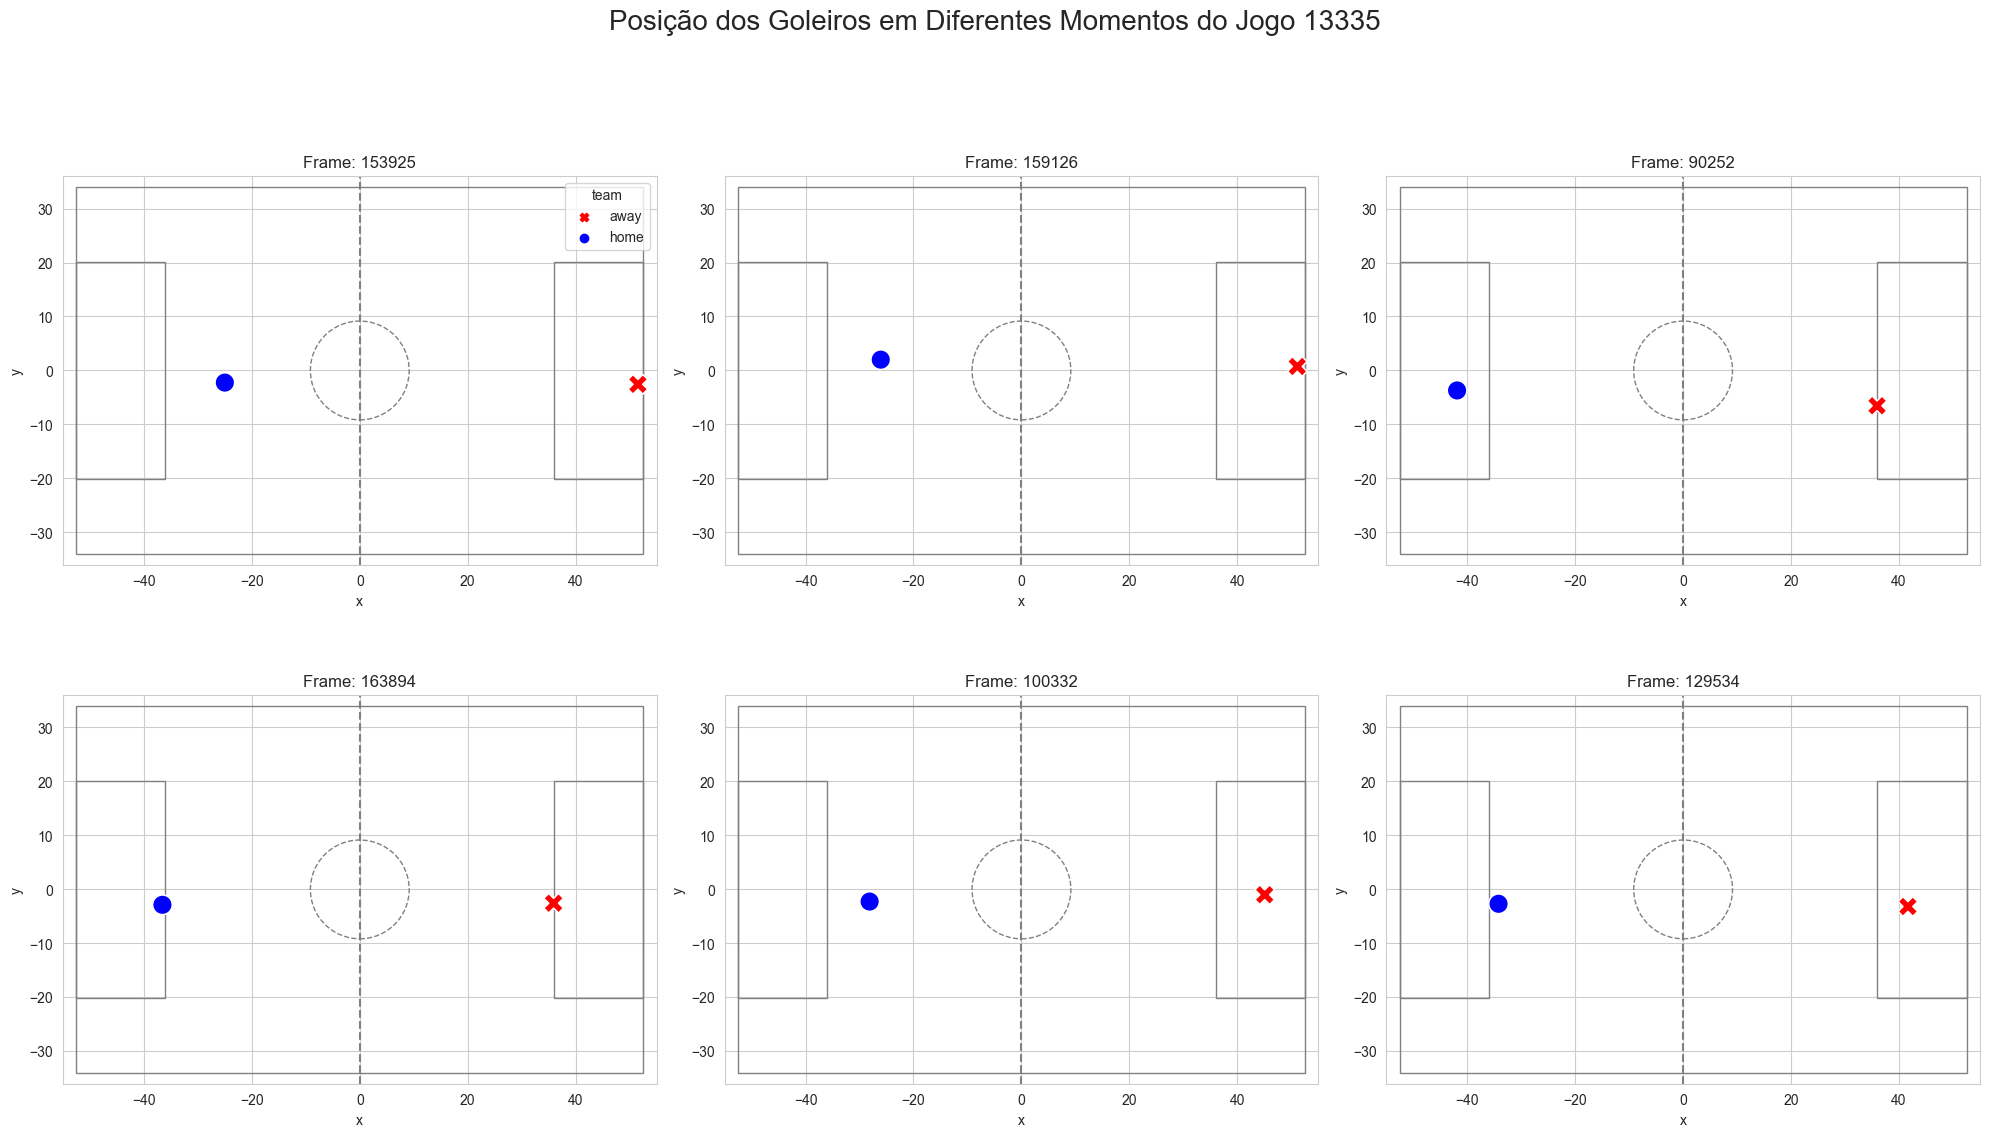

In [8]:
# %% [markdown]
# # Análise Visual da Posição dos Goleiros
# 
# **Objetivo:** Verificar e visualizar a posição dos goleiros do Jogo 13335 em diferentes momentos da partida para confirmar que os dados de tracking estão consistentes e que nossa identificação está correta.

# %%
# --- 1. Importações e Configurações ---
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

# Configurações de visualização
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (20, 12)

# %%
# --- 2. Definição de Constantes e Carregamento dos Dados ---

# Informações que você forneceu sobre o Jogo 13335
MATCH_ID = 13335
HOME_TEAM_NAME = 'home' # Time 5
AWAY_TEAM_NAME = 'away' # Time 11
HOME_KEEPER_SHIRT = 1
AWAY_KEEPER_SHIRT = 31

# Caminho para o arquivo de tracking já padronizado
tracking_path = f'parquets_standardizados/{MATCH_ID}_standard.parquet'

# Carregar os dados
try:
    df_tracking = pd.read_parquet(tracking_path)
    print(f"Arquivo de tracking para o jogo {MATCH_ID} carregado com sucesso.")
    print(f"Total de registros: {len(df_tracking):,}")
except FileNotFoundError:
    raise FileNotFoundError(f"Arquivo não encontrado em '{tracking_path}'. Certifique-se que o caminho está correto.")

# %%
# --- 3. Identificar e Filtrar os Goleiros ---

# Cria uma máscara booleana para encontrar o goleiro do time da casa
mask_home_keeper = (df_tracking['team'] == HOME_TEAM_NAME) & (df_tracking['shirt'] == HOME_KEEPER_SHIRT)

# Cria uma máscara booleana para encontrar o goleiro do time visitante
mask_away_keeper = (df_tracking['team'] == AWAY_TEAM_NAME) & (df_tracking['shirt'] == AWAY_KEEPER_SHIRT)

# Combina as máscaras para obter um DataFrame apenas com os registros dos dois goleiros
df_keepers = df_tracking[mask_home_keeper | mask_away_keeper].copy()

print(f"\nEncontrados {len(df_keepers):,} registros pertencentes aos goleiros.")
display(df_keepers.head())

# %%
# --- 4. Visualização em Múltiplos Frames ---

# Função auxiliar para desenhar o campo de futebol
def draw_pitch(ax):
    """Desenha um campo de futebol simples no eixo fornecido (coordenadas em metros)."""
    ax.add_patch(plt.Rectangle((-52.5, -34), 105, 68, fill=None, edgecolor='gray', lw=1))
    ax.axvline(0, color='gray', linestyle='--')
    ax.add_patch(plt.Circle((0, 0), 9.15, fill=None, edgecolor='gray', ls='--'))
    # Adiciona as grandes áreas
    ax.add_patch(plt.Rectangle((-52.5, -20.15), 16.5, 40.3, fill=None, edgecolor='gray'))
    ax.add_patch(plt.Rectangle((36, -20.15), 16.5, 40.3, fill=None, edgecolor='gray'))
    ax.set_xlim(-55, 55)
    ax.set_ylim(-36, 36)
    ax.set_aspect('equal', adjustable='box')


# Seleciona 6 frames espaçados uniformemente ao longo do jogo para visualizar
unique_frames = df_keepers['frame_id'].unique()
# Garante que pegamos no máximo 6 frames, mesmo que o jogo seja curto
num_samples = min(6, len(unique_frames))
# sample_frames = unique_frames[np.linspace(0, len(unique_frames) - 1, num_samples, dtype=int)]
# random
sample_frames = np.random.choice(unique_frames, num_samples, replace=False)

# Cria a grade de plots 2x3
fig, axes = plt.subplots(2, 3)
fig.suptitle(f'Posição dos Goleiros em Diferentes Momentos do Jogo {MATCH_ID}', fontsize=20)
axes = axes.flatten() # Transforma a matriz 2x3 em um array de 6 para facilitar o loop

for i, frame_id in enumerate(sample_frames):
    ax = axes[i]
    draw_pitch(ax) # Desenha o campo
    
    # Filtra os dados para o frame atual
    df_frame = df_keepers[df_keepers['frame_id'] == frame_id]
    
    # Plota os goleiros no gráfico
    sns.scatterplot(
        data=df_frame, 
        x='x', 
        y='y', 
        hue='team', # Cores diferentes para 'home' e 'away'
        palette={'home': 'blue', 'away': 'red'},
        style='team', # Marcadores diferentes
        markers={'home': 'o', 'away': 'X'},
        s=200, # Tamanho do marcador
        ax=ax,
        legend= (i == 0) # Mostra a legenda apenas no primeiro gráfico
    )
    
    ax.set_title(f"Frame: {int(frame_id)}")

plt.tight_layout(rect=[0, 0, 1, 0.96]) # Ajusta o layout para o título principal
plt.show()

In [9]:
df_tracking[df_tracking.frame_id == 129534]

,elapsed_seconds,frame_id,match_id,period,shirt,x,y,team,ball_x,ball_y,ball_z,vx,vy,ax,ay,speed
14445,1112.379122,129534,NaN,2,2,17.229,9.328,away,2.82,-15.36,0.06,-0.269728,0.239758,-8.083663,7.185478,0.360883
15060,1112.379122,129534,NaN,2,6,18.306,-10.245,away,2.82,-15.36,0.06,0.419576,-0.749243,12.574587,-22.454619,0.858726
15522,1112.379122,129534,NaN,2,8,8.374,-16.499,away,2.82,-15.36,0.06,0.239758,0.329667,7.185478,9.880032,0.407632
16179,1112.379122,129534,NaN,2,9,1.537,-12.178,away,2.82,-15.36,0.06,-9.080828,3.926035,-272.149979,117.662202,9.893189
16836,1112.379122,129534,NaN,2,16,8.709,-13.084,away,2.82,-15.36,0.06,1.588396,-1.438547,47.603792,-43.112868,2.142993
17493,1112.379122,129534,NaN,2,19,1.324,-14.882,away,2.82,-15.36,0.06,4.465490,-3.896065,133.829528,-116.764018,5.926206
18150,1112.379122,129534,NaN,2,20,1.019,-1.770,away,2.82,-15.36,0.06,0.059939,4.525429,1.796370,135.625897,4.525826
19002,1112.379122,129534,NaN,2,25,18.279,2.033,away,2.82,-15.36,0.06,1.018971,-1.258729,30.538282,-37.723760,1.619475
19659,1112.379122,129534,NaN,2,31,41.643,-3.170,away,2.82,-15.36,0.06,2.037942,0.059939,61.076563,1.796370,2.038823
20316,1112.379122,129534,NaN,2,47,2.853,-16.426,away,2.82,-15.36,0.06,6.023916,2.247730,180.535135,67.363856,6.429607


In [10]:
df_metadata[df_metadata.frame_id == 129534]

,match_id,frame_id,period,elapsed_seconds,home_has_possession,event_id,event_type,event_setpiece_type,event_player_id,event_team_id,event_start_frame,event_end_frame,possession_id,possession_type,possession_start_frame,possession_end_frame,sequence,version,video_time_milli
1018,NaN,129534,2,1112.379122,None,12948477.0,PFF_Frame_GameEventType.ON_THE_BALL,NaN,270.0,5.0,129468.0,129534.0,12942247.0,Frame_PossessionEventType.PASS,129534.0,NaN,None,None,4322122.122


Plotando a posição de 22 jogadores para o Frame 129534...


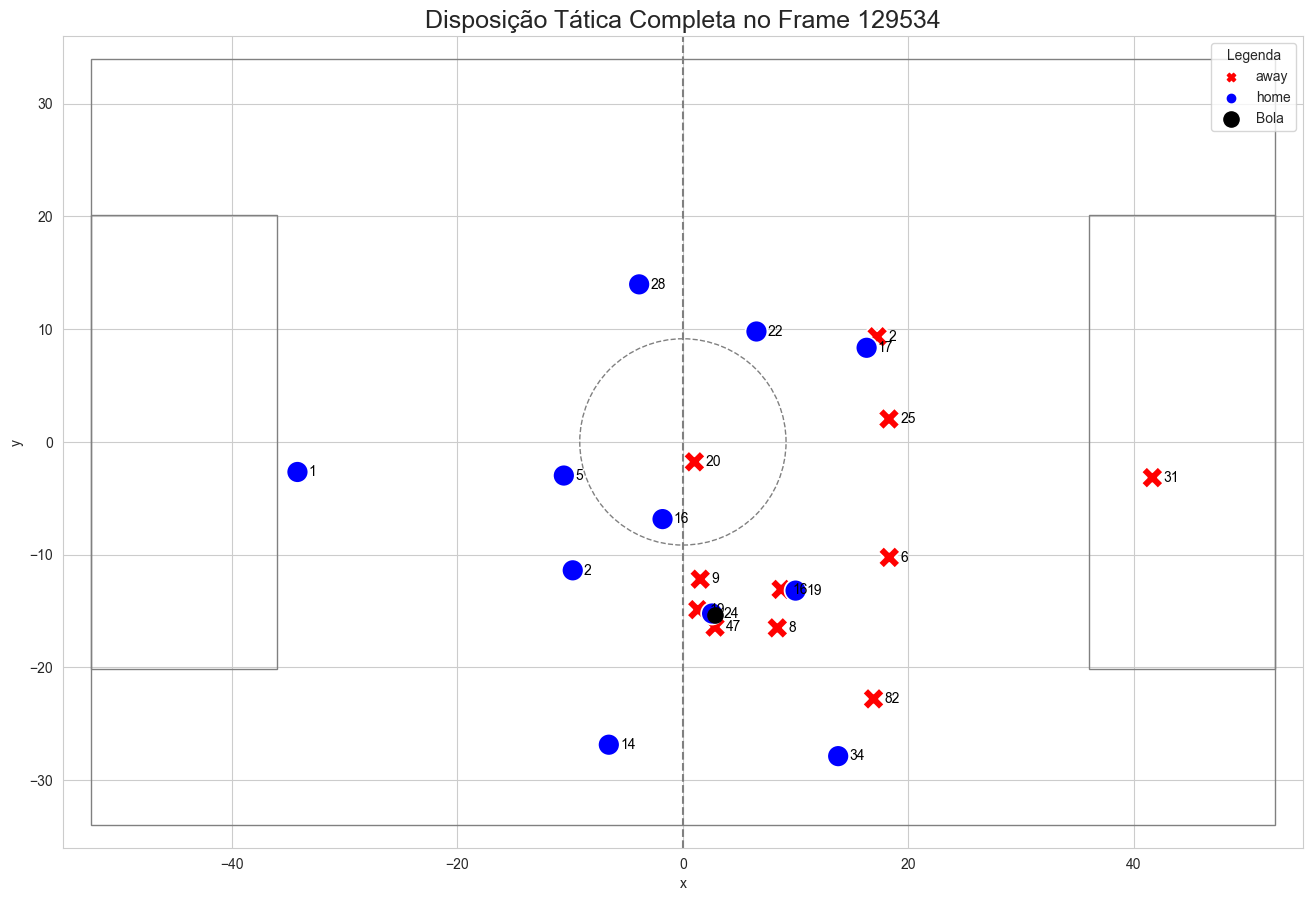

In [11]:
# %% [markdown]
# ### Análise de um Frame Específico (129534)
# 
# *Vamos agora focar em um único momento do jogo para ver a disposição tática completa de ambas as equipes.*

# %%
# --- 1. Definir o Frame e Filtrar os Dados ---
FRAME_ESPECIFICO = 129534

# Filtra o DataFrame de tracking para obter os dados de todos os jogadores neste frame
df_snapshot = df_tracking[df_tracking['frame_id'] == FRAME_ESPECIFICO].copy()

if df_snapshot.empty:
    print(f"Nenhum dado encontrado para o Frame ID: {FRAME_ESPECIFICO}")
else:
    # --- 2. Visualização do Frame ---
    print(f"Plotando a posição de {len(df_snapshot)} jogadores para o Frame {FRAME_ESPECIFICO}...")
    
    # Pega a posição da bola (é a mesma para todas as linhas deste frame)
    posicao_bola = df_snapshot[['ball_x', 'ball_y']].iloc[0]
    
    # Cria a figura e o eixo
    fig, ax = plt.subplots(figsize=(16, 11))
    
    # Usa a mesma função para desenhar o campo que definimos antes
    draw_pitch(ax)
    
    # Plota a posição de todos os jogadores
    sns.scatterplot(
        data=df_snapshot, 
        x='x', 
        y='y', 
        hue='team', # Cores diferentes para 'home' e 'away'
        palette={'home': 'blue', 'away': 'red'},
        style='team', # Marcadores diferentes
        markers={'home': 'o', 'away': 'X'},
        s=250, # Tamanho do marcador
        ax=ax,
        legend='full'
    )
    
    # Plota a bola
    ax.scatter(posicao_bola['ball_x'], posicao_bola['ball_y'], color='black', s=120, label='Bola', zorder=5)
    
    # Adiciona o número da camisa de cada jogador ao lado do seu marcador
    for _, player_row in df_snapshot.iterrows():
        ax.text(player_row['x'] + 1, player_row['y'], str(int(player_row['shirt'])), 
                color='black', fontsize=10, ha='left', va='center')

    ax.set_title(f'Disposição Tática Completa no Frame {FRAME_ESPECIFICO}', fontsize=18)
    ax.legend(title='Legenda', loc='upper right')
    plt.show()